# T3 - Análise de Dados e Visualização do SIASUS

Neste notebook será feita a análise dos dados de produção ambulatorial de Ijuí/RS, referentes a agosto de 2026, utilizando Python e Pandas. Ao final será feita a visualização dos resultados e suas respectivas interpretações

## 1. Carregamento dos dados do banco 

In [1]:
# conexao.py
from getpass import getpass
from mysql.connector import connect, Error

def usar_conexao(acao):
    try:
        with connect(
            host="localhost",        
            user=input("Usuário: "),   
            password=getpass("Senha: "),
            database="siasus"
        ) as connection:
            print("Conexão estabelecida:", connection)
            return acao(connection)
    except Error as e:
        print("Ocorreu um erro ao conectar com o BD: ", e)

In [2]:
import pandas as pd

# Consulta SQL única para recuperar todas as colunas e linhas da VIEW.
def carregar_dados(connection):
    with connection.cursor() as cursor:
        cursor.execute("SELECT * FROM siasus.pa_ijui")
        return pd.DataFrame(cursor.fetchall(), columns=cursor.column_names)

tabela = usar_conexao(carregar_dados)

print("Dimensão da tabela:", tabela.shape)
display(tabela.head())

Conexão estabelecida: <mysql.connector.connection.MySQLConnection object at 0x00000181E120BB60>
Dimensão da tabela: (76755, 17)


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
0,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,QUIMIOTERAPIA DO ADENOCARCINOMA DE PROSTATA RE...,Medico oncologista clinico,M,086,C61,C61 Neopl malig da prostata,Ijui,Santa Barbara,1,1,1062.65,1062.65
1,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,INIBIDOR DA OSTEOLISE,Medico oncologista clinico,M,086,C61,C61 Neopl malig da prostata,Ijui,Santa Barbara,1,1,449.50,449.50
2,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico ginecologista e obstetra,F,042,Z014,Z01.4 Exame ginecologico,Ijui,Humaita,1,1,10.00,10.00
3,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico ginecologista e obstetra,F,042,Z014,Z01.4 Exame ginecologico,Ijui,Humaita,1,1,10.00,10.00
4,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CURATIVO GRAU II C/ OU S/ DEBRIDAMENTO,Medico cardiologista,M,064,I211,I21.1 Infarto agudo transmural parede inf miocard,Ijui,Sao Domingos Do Prata,1,1,32.40,32.40


## 2. Conhecendo os dados

In [3]:
print("Colunas da tabela:")
print(tabela.columns.tolist())

print("\nTipos de dados:")
print(tabela.dtypes)

Colunas da tabela:
['Ano', 'Mes', 'AnoBimestre', 'AnoTrimestre', 'Estabelecimento', 'Procedimento', 'Ocupacao', 'pa_sexo', 'pa_idade', 'pa_cidpri', 'Diagnostico', 'MunicipioEstabelecimento', 'MunicipioPaciente', 'pa_qtdpro', 'pa_qtdapr', 'pa_valpro', 'pa_valapr']

Tipos de dados:
Ano                          int64
Mes                          int64
AnoBimestre                    str
AnoTrimestre                   str
Estabelecimento                str
Procedimento                   str
Ocupacao                       str
pa_sexo                        str
pa_idade                       str
pa_cidpri                      str
Diagnostico                    str
MunicipioEstabelecimento       str
MunicipioPaciente              str
pa_qtdpro                   object
pa_qtdapr                   object
pa_valpro                   object
pa_valapr                   object
dtype: object


In [4]:
colunas_numericas = ["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr"]

for coluna in colunas_numericas:
    tabela[coluna] = pd.to_numeric(tabela[coluna])

print("Tipos de dados após o ajuste:")
print(tabela[colunas_numericas].dtypes)

Tipos de dados após o ajuste:
pa_qtdpro    float64
pa_qtdapr    float64
pa_valpro    float64
pa_valapr    float64
dtype: object


In [5]:
display(tabela[colunas_numericas].describe())

,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
count,76755.000000,76755.000000,76755.000000,76755.000000
mean,6.533385,4.867735,82.452588,78.088662
std,29.158853,27.172253,507.091080,504.598108
min,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,3.370000,0.000000
50%,1.000000,1.000000,6.740000,3.370000
75%,1.000000,1.000000,17.670000,12.340000
max,3000.000000,3000.000000,14681.600000,14681.600000


In [6]:
print("Estabelecimentos com mais registros:")
display(tabela["Estabelecimento"].value_counts().head(10))

print("Distribuição por sexo:")
display(tabela["pa_sexo"].value_counts())

Estabelecimentos com mais registros:


Estabelecimento
HOSPITAL BOM PASTOR IJUI                               30387
HOSPITAL DE CLINICAS IJUI                              23650
17 COORDENADORIA REGIONAL DE SAUDE                      7590
CER III UNIR                                            4504
POSTO CENTRAL SECRETARIA MUNICIPAL DE SAUDE DE IJUI     3169
APAE IJUI                                               2734
CENTRO AUDITIVO PROAUDI                                 1931
CISA                                                    1782
SAE SERVICO DE ATENDIMENTO ESPECIALIZADO                 519
CENTRO DE ESPECIALIDADES ODONTOLOGICAS SMS IJUI          362
Name: count, dtype: int64

Distribuição por sexo:


pa_sexo
F     40387
M     32811
0      3556
01        1
Name: count, dtype: int64

Foi identificado um registro com o código 01 na coluna de sexo, que não corresponde aos valores esperados (F, M e 0). Como apareceu apenas uma vez, foi considerado um valor fora do padrão e não foi classificado como feminino, masculino ou não exigido.

Verificando valores ausentes

In [7]:
nulos = tabela.isna().sum().sort_values(ascending=False)

print("Quantidade de valores ausentes por coluna:")
display(nulos.to_frame("Valores ausentes"))

Quantidade de valores ausentes por coluna:


,Valores ausentes
Diagnostico,7
MunicipioPaciente,1
Ocupacao,1
Ano,0
Mes,0
Estabelecimento,0
Procedimento,0
AnoTrimestre,0
AnoBimestre,0
pa_idade,0


In [8]:
registros_nulos = tabela[tabela.isna().any(axis=1)]

print("Registros que possuem valores ausentes:")
display(registros_nulos)

Registros que possuem valores ausentes:


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
17881,2026,8,2026B4,2026T3,17 COORDENADORIA REGIONAL DE SAUDE,DAPAGLIFLOZINA 10 MG (POR COMPRIMIDO),Farmaceutico,F,064,N183,NaN,Ijui,Ijui,30.0,0.0,0.0,0.0
18038,2026,8,2026B4,2026T3,17 COORDENADORIA REGIONAL DE SAUDE,DAPAGLIFLOZINA 10 MG (POR COMPRIMIDO),Farmaceutico,F,060,N183,NaN,Ijui,Joia,30.0,0.0,0.0,0.0
18040,2026,8,2026B4,2026T3,17 COORDENADORIA REGIONAL DE SAUDE,DAPAGLIFLOZINA 10 MG (POR COMPRIMIDO),Farmaceutico,M,031,N183,NaN,Ijui,Joia,30.0,0.0,0.0,0.0
18146,2026,8,2026B4,2026T3,17 COORDENADORIA REGIONAL DE SAUDE,DAPAGLIFLOZINA 10 MG (POR COMPRIMIDO),Farmaceutico,F,056,N183,NaN,Ijui,Ijui,30.0,0.0,0.0,0.0
18147,2026,8,2026B4,2026T3,17 COORDENADORIA REGIONAL DE SAUDE,DAPAGLIFLOZINA 10 MG (POR COMPRIMIDO),Farmaceutico,M,054,N183,NaN,Ijui,Ijui,30.0,0.0,0.0,0.0
18304,2026,8,2026B4,2026T3,17 COORDENADORIA REGIONAL DE SAUDE,DAPAGLIFLOZINA 10 MG (POR COMPRIMIDO),Farmaceutico,M,064,N183,NaN,Ijui,Condor,30.0,30.0,0.0,0.0
67487,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,ELETROCARDIOGRAMA,NaN,01,0,0000,CID NAO INFORMADO,Ijui,NaN,0.0,5.0,0.0,0.0
75278,2026,8,2026B4,2026T3,17 COORDENADORIA REGIONAL DE SAUDE,DAPAGLIFLOZINA 10 MG (POR COMPRIMIDO),Farmaceutico,F,040,N184,NaN,Ijui,Panambi,30.0,0.0,0.0,0.0


Os registros com informações ausentes foram mantidos, pois não seria adequado excluir dados que ainda possuem outras informações válidas. As ausências estão relacionadas principalmente a códigos sem correspondência nas tabelas auxiliares.

In [9]:
print("Quantidade de registros duplicados:", tabela.duplicated().sum())

Quantidade de registros duplicados: 31642


In [10]:
duplicados = tabela[tabela.duplicated(keep=False)]

print("Total de registros envolvidos em duplicações:", len(duplicados))
display(duplicados.head(10))

Total de registros envolvidos em duplicações: 44465


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,Procedimento,Ocupacao,pa_sexo,pa_idade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
2,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico ginecologista e obstetra,F,042,Z014,Z01.4 Exame ginecologico,Ijui,Humaita,1.0,1.0,10.00,10.00
3,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico ginecologista e obstetra,F,042,Z014,Z01.4 Exame ginecologico,Ijui,Humaita,1.0,1.0,10.00,10.00
11,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Enfermeiro,F,042,0000,CID NAO INFORMADO,Ijui,Humaita,1.0,1.0,6.30,6.30
14,2026,8,2026B4,2026T3,HOSPITAL DE CLINICAS IJUI,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Enfermeiro,F,042,0000,CID NAO INFORMADO,Ijui,Humaita,1.0,1.0,6.30,6.30
18,2026,8,2026B4,2026T3,CER III UNIR,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico oftalmologista,M,044,H52,H52 Transt da refracao e da acomodacao,Ijui,Ijui,1.0,1.0,10.00,10.00
19,2026,8,2026B4,2026T3,CER III UNIR,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico oftalmologista,F,074,H542,H54.2 Visao subnormal de ambos os olhos,Ijui,Ijui,1.0,1.0,10.00,10.00
20,2026,8,2026B4,2026T3,CER III UNIR,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico oftalmologista,M,034,H542,H54.2 Visao subnormal de ambos os olhos,Ijui,Ijui,1.0,0.0,10.00,0.00
21,2026,8,2026B4,2026T3,CER III UNIR,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico neurologista,M,017,F900,F90.0 Disturbios da atividade e da atencao,Ijui,Crissiumal,1.0,0.0,10.00,0.00
23,2026,8,2026B4,2026T3,CER III UNIR,TRATAMENTO INTENSIVO DE PACIENTE EM REABILITAC...,Nutricionista,F,057,G824,G82.4 Tetraplegia espastica,Ijui,Ijui,1.0,1.0,21.69,21.69
24,2026,8,2026B4,2026T3,CER III UNIR,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,Medico oftalmologista,M,034,H542,H54.2 Visao subnormal de ambos os olhos,Ijui,Ijui,1.0,0.0,10.00,0.00


## 3. Limpeza e preparação dos dados

Nesta etapa, foram verificadas informações ausentes e valores inválidos, buscando organizar os dados para as análises.

In [11]:
tabela["Sexo"] = tabela["pa_sexo"].map({
    "F": "Feminino",
    "M": "Masculino"
}).fillna("Não informado ou inválido")

display(tabela["Sexo"].value_counts())

Sexo
Feminino                     40387
Masculino                    32811
Não informado ou inválido     3557
Name: count, dtype: int64

In [12]:
idade = pd.to_numeric(tabela["pa_idade"], errors="coerce")

idade_valida = idade.mask(idade == 999)

tabela["FaixaEtaria"] = pd.cut(
    idade_valida,
    bins=[-1, 17, 29, 59, 120],
    labels=["0 a 17 anos", "18 a 29 anos", "30 a 59 anos", "60 anos ou mais"]
)

tabela["FaixaEtaria"] = tabela["FaixaEtaria"].cat.add_categories(
    ["Não informada"]
).fillna("Não informada")

perfil_idade = tabela["FaixaEtaria"].value_counts().sort_index().to_frame("Registros")

perfil_idade["Percentual"] = (
    perfil_idade["Registros"] / len(tabela) * 100
)

display(
    perfil_idade.style.format({
        "Registros": "{:,.0f}",
        "Percentual": "{:.2f}%"
    }, decimal=",", thousands=".")
)

,Registros,Percentual
FaixaEtaria,,
0 a 17 anos,7.795,"10,16%"
18 a 29 anos,4.081,"5,32%"
30 a 59 anos,23.576,"30,72%"
60 anos ou mais,40.556,"52,84%"
Não informada,747,"0,97%"


In [13]:
print("Idades não informadas (código 999):", (idade == 999).sum())
print("Idades acima de 100 anos (exceto 999):", ((idade > 100) & (idade < 999)).sum())
print("Idades ausentes (nulos):", idade.isna().sum())

Idades não informadas (código 999): 747
Idades acima de 100 anos (exceto 999): 1
Idades ausentes (nulos): 0


In [14]:
print("Total de registros:", len(tabela))
print("Registros duplicados:", tabela.duplicated().sum())
print("Registros envolvidos em duplicidades:", tabela.duplicated(keep=False).sum())

Total de registros: 76755
Registros duplicados: 31642
Registros envolvidos em duplicidades: 44465


A verificação identificou 31.642 registros aparentemente duplicados. Porém, como a análise utiliza uma VIEW com apenas parte das colunas da tabela original, não é possível confirmar que esses registros sejam duplicações reais. Por isso, foram mantidos para evitar a exclusão indevida de informações.

In [15]:
print("Valores ausentes por coluna:")
display(tabela.isnull().sum())

Valores ausentes por coluna:


Ano                         0
Mes                         0
AnoBimestre                 0
AnoTrimestre                0
Estabelecimento             0
Procedimento                0
Ocupacao                    1
pa_sexo                     0
pa_idade                    0
pa_cidpri                   0
Diagnostico                 7
MunicipioEstabelecimento    0
MunicipioPaciente           1
pa_qtdpro                   0
pa_qtdapr                   0
pa_valpro                   0
pa_valapr                   0
Sexo                        0
FaixaEtaria                 0
dtype: int64

A verificação final identificou 9 valores ausentes, distribuídos entre ocupação, diagnóstico e município do paciente. Esses registros foram mantidos, pois possuem outras informações válidas e sua exclusão poderia causar perda de dados.

## 4. Análise da produção ambulatorial

In [16]:
geral = pd.DataFrame([{
    "Registros": len(tabela),
    "Quantidade apresentada": tabela["pa_qtdpro"].sum(),
    "Quantidade aprovada": tabela["pa_qtdapr"].sum(),
    "Valor apresentado": tabela["pa_valpro"].sum(),
    "Valor aprovado": tabela["pa_valapr"].sum(),
    "Diferença financeira": tabela["pa_valpro"].sum() - tabela["pa_valapr"].sum()
}])

display(
    geral.style.format({
        "Quantidade apresentada": "{:,.0f}",
        "Quantidade aprovada": "{:,.0f}",
        "Valor apresentado": "R$ {:,.2f}",
        "Valor aprovado": "R$ {:,.2f}",
        "Diferença financeira": "R$ {:,.2f}"
    }, decimal=",", thousands=".")
)

,Registros,Quantidade apresentada,Quantidade aprovada,Valor apresentado,Valor aprovado,Diferença financeira
0,76.755,501.470,373.623,"R$ 6.328.648,38","R$ 5.993.695,25","R$ 334.953,13"


No mês de agosto de 2026, foram registrados 76.755 atendimentos, totalizando 501.470 procedimentos apresentados e 373.623 aprovados. A diferença entre o valor apresentado (R$ 6.328.648,38) e o valor aprovado (R$ 5.993.695,25) foi de R$ 334.953,13.

### Produção por período

In [17]:
mensal = (
    tabela.groupby(
        ["Ano", "Mes", "AnoBimestre", "AnoTrimestre"],
        as_index=False
    )
    .agg(
        Registros=("Procedimento", "size"),
        QuantidadeApresentada=("pa_qtdpro", "sum"),
        QuantidadeAprovada=("pa_qtdapr", "sum"),
        ValorApresentado=("pa_valpro", "sum"),
        ValorAprovado=("pa_valapr", "sum")
    )
)

display(
    mensal.style.format({
        "QuantidadeApresentada": "{:,.0f}",
        "QuantidadeAprovada": "{:,.0f}",
        "ValorApresentado": "R$ {:,.2f}",
        "ValorAprovado": "R$ {:,.2f}",
    }, decimal=",", thousands=".")
)

,Ano,Mes,AnoBimestre,AnoTrimestre,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,2.026,8,2026B4,2026T3,76.755,501.470,373.623,"R$ 6.328.648,38","R$ 5.993.695,25"


### Procedimentos mais frequentes

In [18]:
procedimentos = (
    tabela.groupby("Procedimento", as_index=False)
    .agg(
        Registros=("Procedimento", "size"),
        QuantidadeApresentada=("pa_qtdpro", "sum"),
        QuantidadeAprovada=("pa_qtdapr", "sum")
    )
    .sort_values("Registros", ascending=False)
)

display(
    procedimentos.head(10).style.format({
        "Registros": "{:,.0f}",
        "QuantidadeApresentada": "{:,.0f}",
        "QuantidadeAprovada": "{:,.0f}"
    }, decimal=",", thousands=".")
)

,Procedimento,Registros,QuantidadeApresentada,QuantidadeAprovada
160,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,11.291,26.259,21.358
157,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA ATENCAO ESPECIALIZADA (EXCETO MEDICO),10.613,35.309,30.160
117,CERATOMETRIA,3.354,3.354,1.400
85,BIOMICROSCOPIA DE FUNDO DE OLHO,3.354,3.354,1.400
722,TESTE DE VISAO DE CORES,3.354,3.354,1.400
410,MAPEAMENTO DE RETINA,3.354,3.354,1.200
502,POTENCIAL DE ACUIDADE VISUAL,3.353,3.353,1.400
19,ADMINISTRACAO DE MEDICAMENTOS NA ATENCAO ESPECIALIZADA.,2.493,4.021,2.075
49,ATENDIMENTO / ACOMPANHAMENTO DE PACIENTE EM REABILITACAO DO DESENVOLVIMENTO NEUROPSICOMOTOR,1.749,1.749,1.460
328,FORMOTEROL 12 MCG + BUDESONIDA 400 MCG Ã¿(POR CAPSULA INALANTE),1.636,101.432,26.714


### Produção por estabelecimento

In [19]:
estabelecimentos = (
    tabela.groupby("Estabelecimento", as_index=False)
    .agg(
        Registros=("Procedimento", "size"),
        QuantidadeApresentada=("pa_qtdpro", "sum"),
        QuantidadeAprovada=("pa_qtdapr", "sum"),
        ValorApresentado=("pa_valpro", "sum"),
        ValorAprovado=("pa_valapr", "sum")
    )
    .sort_values("QuantidadeAprovada", ascending=False)
)

display(
    estabelecimentos.head(10).style.format({
        "Registros": "{:,.0f}",
        "QuantidadeApresentada": "{:,.0f}",
        "QuantidadeAprovada": "{:,.0f}",
        "ValorApresentado": "R$ {:,.2f}",
        "ValorAprovado": "R$ {:,.2f}",
    }, decimal=",", thousands=".")
)

,Estabelecimento,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,17 COORDENADORIA REGIONAL DE SAUDE,7.590,326.558,232.604,"R$ 1.561.430,32","R$ 1.557.603,56"
9,POSTO CENTRAL SECRETARIA MUNICIPAL DE SAUDE DE IJUI,3.169,52.110,48.217,"R$ 458.650,70","R$ 420.921,60"
8,HOSPITAL DE CLINICAS IJUI,23.650,46.139,38.241,"R$ 3.185.883,83","R$ 3.060.572,89"
6,CISA,1.782,31.053,24.976,"R$ 225.550,97","R$ 165.773,67"
7,HOSPITAL BOM PASTOR IJUI,30.387,30.401,15.403,"R$ 338.071,45","R$ 242.757,25"
5,CER III UNIR,4.504,4.856,4.428,"R$ 246.897,44","R$ 240.915,04"
10,SAE SERVICO DE ATENDIMENTO ESPECIALIZADO,519,3.832,3.523,"R$ 7.998,10","R$ 6.103,20"
1,APAE IJUI,2.734,2.734,2.445,"R$ 48.309,78","R$ 43.203,15"
2,CENTRO AUDITIVO PROAUDI,1.931,2.408,2.407,"R$ 253.557,59","R$ 253.546,69"
3,CENTRO DE ESPECIALIDADES ODONTOLOGICAS SMS IJUI,362,1.213,1.213,"R$ 1.751,70","R$ 1.751,70"


In [20]:
estabelecimentos["Diferenca"] = (
    estabelecimentos["QuantidadeApresentada"] -
    estabelecimentos["QuantidadeAprovada"]
)

estabelecimentos["PercentualAprovado"] = (
    estabelecimentos["QuantidadeAprovada"] /
    estabelecimentos["QuantidadeApresentada"] * 100
)

display(
    estabelecimentos[
        ["Estabelecimento", "QuantidadeApresentada",
         "QuantidadeAprovada", "Diferenca", "PercentualAprovado"]
    ].head(10).style.format({
        "QuantidadeApresentada": "{:,.0f}",
        "QuantidadeAprovada": "{:,.0f}",
        "Diferenca": "{:,.0f}",
        "PercentualAprovado": "{:.2f}%"
    }, decimal=",", thousands=".")
)

,Estabelecimento,QuantidadeApresentada,QuantidadeAprovada,Diferenca,PercentualAprovado
0,17 COORDENADORIA REGIONAL DE SAUDE,326.558,232.604,93.954,"71,23%"
9,POSTO CENTRAL SECRETARIA MUNICIPAL DE SAUDE DE IJUI,52.110,48.217,3.893,"92,53%"
8,HOSPITAL DE CLINICAS IJUI,46.139,38.241,7.898,"82,88%"
6,CISA,31.053,24.976,6.077,"80,43%"
7,HOSPITAL BOM PASTOR IJUI,30.401,15.403,14.998,"50,67%"
5,CER III UNIR,4.856,4.428,428,"91,19%"
10,SAE SERVICO DE ATENDIMENTO ESPECIALIZADO,3.832,3.523,309,"91,94%"
1,APAE IJUI,2.734,2.445,289,"89,43%"
2,CENTRO AUDITIVO PROAUDI,2.408,2.407,1,"99,96%"
3,CENTRO DE ESPECIALIDADES ODONTOLOGICAS SMS IJUI,1.213,1.213,0,"100,00%"


A 17ª Coordenadoria Regional de Saúde concentra o maior volume de procedimentos aprovados (232.604), seguida pelo Posto Central e pelo Hospital de Clínicas de Ijuí. Em termos financeiros, o Hospital de Clínicas de Ijuí responde pelo maior valor aprovado (R$ 3.060.572,89).

In [21]:
print("Valores de idade encontrados:")
print(sorted(tabela["pa_idade"].dropna().unique()))

Valores de idade encontrados:
['0', '000', '001', '002', '003', '004', '005', '006', '007', '008', '009', '010', '011', '012', '013', '014', '015', '016', '017', '018', '019', '020', '021', '022', '023', '024', '025', '026', '027', '028', '029', '030', '031', '032', '033', '034', '035', '036', '037', '038', '039', '040', '041', '042', '043', '044', '045', '046', '047', '048', '049', '050', '051', '052', '053', '054', '055', '056', '057', '058', '059', '060', '061', '062', '063', '064', '065', '066', '067', '068', '069', '070', '071', '072', '073', '074', '075', '076', '077', '078', '079', '080', '081', '082', '083', '084', '085', '086', '087', '088', '089', '090', '091', '092', '093', '094', '095', '096', '097', '098', '099', '100', '106', '999']


In [22]:
perfil_sexo = tabela["pa_sexo"].value_counts().to_frame("Registros")

perfil_sexo["Percentual"] = (
    perfil_sexo["Registros"] / len(tabela) * 100
)

display(
    perfil_sexo.style.format({
        "Registros": "{:,.0f}",
        "Percentual": "{:.2f}%"
    }, decimal=",", thousands=".")
)

,Registros,Percentual
pa_sexo,,
F,40.387,"52,62%"
M,32.811,"42,75%"
0,3.556,"4,63%"
01,1,"0,00%"


A maioria dos atendimentos corresponde a pacientes com 60 anos ou mais (52,84%) e do sexo feminino (52,62%). Foram identificados 747 registros sem idade informada (código 999) e 3.557 sem informação válida de sexo.

In [23]:
diagnosticos = (
    tabela[
        ~tabela["Diagnostico"].isin([
            "CID NAO INFORMADO",
            "CID N O IDENTIFICADO"
        ])
    ]
    .groupby("Diagnostico")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Registros")
)

display(
    diagnosticos.style.format({
        "Registros": "{:,.0f}"
    }, decimal=",", thousands=".")
)

,Registros
Diagnostico,
H90.5 Perda de audicao neuro-sensorial NE,1.761
I51.6 Doenc cardiovascular NE,1.225
F84.9 Transt globais NE do desenvolv,1.204
F84.0 Autismo infantil,989
R52.0 Dor aguda,820
H54.2 Visao subnormal de ambos os olhos,798
J45.0 Asma predom alergica,775
C50.1 Porcao central da mama,613
R52.9 Dor NE,562


Grande parte dos registros aparece sem diagnóstico especificado (CID NAO INFORMADO, com 52.542 registros, cerca de 68% do total). Considerando os diagnósticos identificados, destacam-se perda de audição neuro-sensorial, doenças cardiovasculares e transtornos do desenvolvimento/autismo.

In [24]:
municipios = (
    tabela["MunicipioPaciente"]
    .fillna("Não informado")
    .value_counts()
    .head(10)
    .to_frame("Registros")
)

display(
    municipios.style.format({
        "Registros": "{:,.0f}",
    }, decimal=",", thousands=".")
)

municipio = (
    tabela["MunicipioPaciente"]
    .str.strip()
    .str.upper()
    .str.replace("Í", "I")
)

total_outros = (
    municipio.notna()
    & ~municipio.isin(["IJUI", "INVALIDO"])
).sum()

print("Registros de atendimentos de pacientes residentes em Ijuí:", (municipio == "IJUI").sum())
print("Registros de atendimentos de pacientes residentes em outros municípios:", total_outros)
print("Registros com município inválido:", (municipio == "INVALIDO").sum())
print("Registros sem município informado:", municipio.isna().sum())

,Registros
MunicipioPaciente,
Ijui,34.629
Invalido,3.556
Panambi,3.347
Joia,3.112
Catuipe,2.549
Crissiumal,2.428
Augusto Pestana,2.134
Santo Augusto,1.937
Condor,1.421


Registros de atendimentos de pacientes residentes em Ijuí: 34629
Registros de atendimentos de pacientes residentes em outros municípios: 38569
Registros com município inválido: 3556
Registros sem município informado: 1


Dos registros analisados, 34.629 são de pacientes residentes em Ijuí, enquanto 38.569 pertencem a moradores de outros municípios da região (como Panambi, Jóia e Catuípe), evidenciando o papel de Ijuí como polo regional de saúde.

In [25]:
custo_medio = tabela["pa_valapr"].sum() / tabela["pa_qtdapr"].sum()

resumo = pd.DataFrame([{
    "Valor total aprovado": tabela["pa_valapr"].sum(),
    "Quantidade aprovada": tabela["pa_qtdapr"].sum(),
    "Custo médio por procedimento aprovado": custo_medio
}])

display(
    resumo.style.format({
        "Valor total aprovado": "R$ {:,.2f}",
        "Quantidade aprovada": "{:,.0f}",
        "Custo médio por procedimento aprovado": "R$ {:,.2f}"
    }, decimal=",", thousands=".")
)

,Valor total aprovado,Quantidade aprovada,Custo médio por procedimento aprovado
0,"R$ 5.993.695,25",373.623,"R$ 16,04"


In [26]:
oncologia = tabela[
    tabela["Procedimento"].str.contains(
        "quimioterapia|radioterapia",
        case=False,
        na=False
    )
]

resumo_oncologia = oncologia[["Procedimento", "pa_qtdapr", "pa_valapr"]].head(10)

display(
    resumo_oncologia.style.format({
        "pa_qtdapr": "{:,.0f}",
        "pa_valapr": "R$ {:,.2f}"
    }, decimal=",", thousands=".")
)

print("Registros relacionados à oncologia:", len(oncologia))

,Procedimento,pa_qtdapr,pa_valapr
0,QUIMIOTERAPIA DO ADENOCARCINOMA DE PROSTATA RESISTENTE A HORMONIOTERAPIA,1,"R$ 1.062,65"
5863,QUIMIOTERAPIA DO ADENOCARCINOMA DE PROSTATA RESISTENTE A HORMONIOTERAPIA,0,"R$ 0,00"
5864,QUIMIOTERAPIA DO ADENOCARCINOMA DE PROSTATA RESISTENTE A HORMONIOTERAPIA,0,"R$ 0,00"
5865,QUIMIOTERAPIA DO ADENOCARCINOMA DE PROSTATA RESISTENTE A HORMONIOTERAPIA,0,"R$ 0,00"
5869,QUIMIOTERAPIA DE DOENCA MIELOPROLIFERATIVA RARA - 1Â¦ LINHA,1,"R$ 150,00"
5870,QUIMIOTERAPIA DE DOENCA MIELOPROLIFERATIVA RARA - 1Â¦ LINHA,0,"R$ 0,00"
5871,QUIMIOTERAPIA DE DOENCA MIELOPROLIFERATIVA RARA - 1Â¦ LINHA,0,"R$ 0,00"
5872,QUIMIOTERAPIA DE DOENCA MIELOPROLIFERATIVA RARA - 1Â¦ LINHA,1,"R$ 150,00"
5873,QUIMIOTERAPIA DE DOENCA MIELOPROLIFERATIVA RARA - 1Â¦ LINHA,0,"R$ 0,00"
5874,QUIMIOTERAPIA DE DOENCA MIELOPROLIFERATIVA RARA - 1Â¦ LINHA,0,"R$ 0,00"


Registros relacionados à oncologia: 846


In [27]:
print("Quantidade apresentada:", oncologia["pa_qtdpro"].sum())
print("Quantidade aprovada:", oncologia["pa_qtdapr"].sum())
print("Valor apresentado: R$", round(oncologia["pa_valpro"].sum(), 2))
print("Valor aprovado: R$", round(oncologia["pa_valapr"].sum(), 2))

Quantidade apresentada: 739.0
Quantidade aprovada: 739.0
Valor apresentado: R$ 1381670.03
Valor aprovado: R$ 1381670.03


In [28]:
saude_mental = tabela[
    tabela["Procedimento"].str.contains(
        "psiquiatr|psicolog",
        case=False,
        na=False
    )
]

print("Registros relacionados à saúde mental:", len(saude_mental))
print("Quantidade apresentada:", saude_mental["pa_qtdpro"].sum())
print("Quantidade aprovada:", saude_mental["pa_qtdapr"].sum())
print("Valor apresentado: R$", round(saude_mental["pa_valpro"].sum(), 2))
print("Valor aprovado: R$", round(saude_mental["pa_valapr"].sum(), 2))

Registros relacionados à saúde mental: 1072
Quantidade apresentada: 1072.0
Quantidade aprovada: 1072.0
Valor apresentado: R$ 18942.24
Valor aprovado: R$ 18942.24


Na área de oncologia (quimioterapia e radioterapia), foram identificados 846 registros, com 100% de aprovação sobre a quantidade apresentada (739 procedimentos) e valor aprovado de R$ 1.381.670,03. Já na saúde mental, foram contabilizados 1.072 atendimentos psiquiátricos e psicológicos aprovados, totalizando R$ 18.942,24.

In [29]:
atencao_basica = tabela[
    tabela["Estabelecimento"].str.contains(
        "POSTO CENTRAL SECRETARIA MUNICIPAL DE SAUDE DE IJUI",
        case=False,
        na=False
    )
    |
    tabela["Procedimento"].str.contains(
        "ATENDIMENTO DE URGENCIA EM ATENCAO BASICA",
        case=False,
        na=False
    )
]

print("Registros relacionados à atenção básica:", len(atencao_basica))
print("Quantidade apresentada:", atencao_basica["pa_qtdpro"].sum())
print("Quantidade aprovada:", atencao_basica["pa_qtdapr"].sum())
print("Valor apresentado: R$", round(atencao_basica["pa_valpro"].sum(), 2))
print("Valor aprovado: R$", round(atencao_basica["pa_valapr"].sum(), 2))

Registros relacionados à atenção básica: 3170
Quantidade apresentada: 52185.0
Quantidade aprovada: 48292.0
Valor apresentado: R$ 458650.7
Valor aprovado: R$ 420921.6


A análise considerou os registros do Posto Central da Secretaria Municipal de Saúde de Ijuí e o procedimento identificado como atendimento de urgência em atenção básica. Foram encontrados 3.170 registros, com 52.185 procedimentos apresentados e 48.292 aprovados. Essa seleção representa os registros identificados por esses critérios na base, não necessariamente toda a produção da atenção básica do município.

In [30]:
cronicas_cid = tabela[
    tabela["Diagnostico"].str.contains(
        "hipertens|diabet",
        case=False,
        na=False
    )
]

print("Registros relacionados à hipertensão e diabetes:", len(cronicas_cid))
display(cronicas_cid["Diagnostico"].value_counts())

Registros relacionados à hipertensão e diabetes: 49


Diagnostico
H36.0 Retinopatia diabetica                           27
I27.0 Hipertensao pulmonar prim                        9
E14   Diabetes mellitus NE                             6
I11.0 Doenc cardiaca hipertensiva c/insuf cardiaca     3
E23.2 Diabetes insipido                                2
E11   Diabetes mellitus nao-insulino-dependemte        1
Outra hipertens o pulmonar secund ria                  1
Name: count, dtype: int64

## 5. Visualização dos resultados

Nesta etapa, foram criados gráficos para facilitar a visualização dos dados e destacar algumas informações sobre a produção ambulatorial de Ijuí. Foram observados os procedimentos realizados, os estabelecimentos, os municípios de origem dos pacientes, o perfil dos pacientes, os diagnósticos e as ocupações.

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações criadas para deixar os gráficos mais bonitos visualmente.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
COR_PRINCIPAL = "#2b5c8f"
COR_SECUNDARIA = "#8fb8de"
COR_DESTAQUE = "#d95f02"

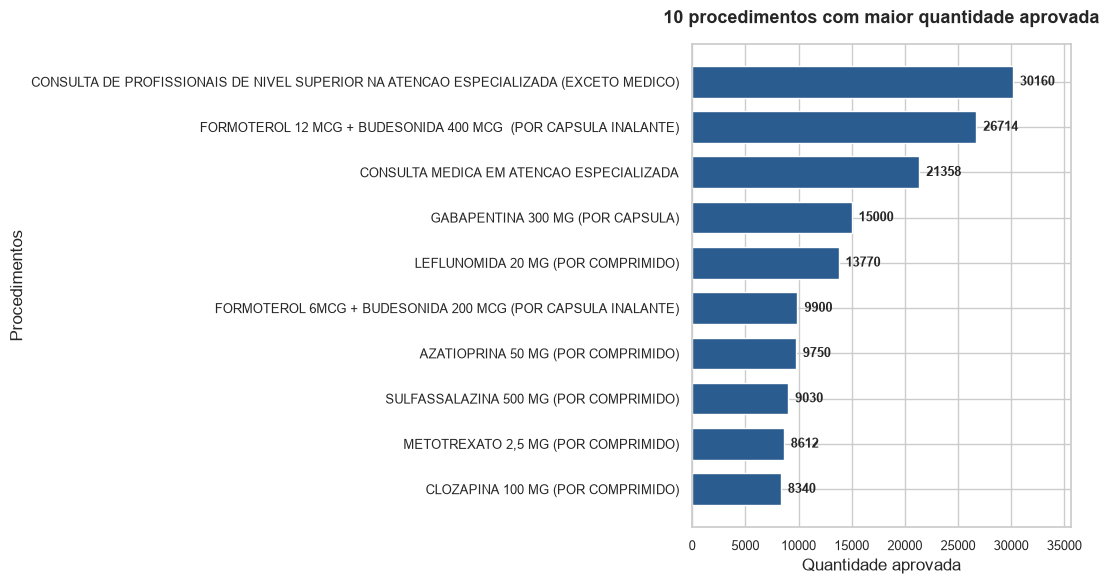

In [32]:
# Procedimentos com maior quantidade aprovada
top_qtd = procedimentos.sort_values(
    "QuantidadeAprovada", ascending=False
).head(10).sort_values("QuantidadeAprovada")

# Ajustando os nomes dos procedimentos
nomes_procedimentos = top_qtd["Procedimento"].str.replace(
    "Ã¿", " ", regex=False
)

# Montando o gráfico
plt.figure(figsize=(11, 6))

barras = plt.barh(
    nomes_procedimentos,
    top_qtd["QuantidadeAprovada"],
    color=COR_PRINCIPAL,
    height=0.7
)

# Valores nas barras
plt.bar_label(
    barras,
    padding=5,
    fmt="%.0f",
    fontsize=9,
    fontweight="bold"
)

plt.title("10 procedimentos com maior quantidade aprovada", pad=15)
plt.xlabel("Quantidade aprovada")
plt.ylabel("Procedimentos")

plt.xticks(fontsize=9)
plt.yticks(fontsize=9)

# Para os valores não ficarem cortados
plt.xlim(0, top_qtd["QuantidadeAprovada"].max() * 1.18)

plt.tight_layout()
plt.show()

O procedimento com maior quantidade aprovada foi a consulta de profissionais de nível superior na atenção especializada (exceto médico) com 30.160 registros. E depois, aparecem o fornecimento de formoterol com budesonida com 26.714 e a consulta médica em atenção especializada com 21.358. Esses foram os procedimentos que mais se destacaram em quantidade aprovada.

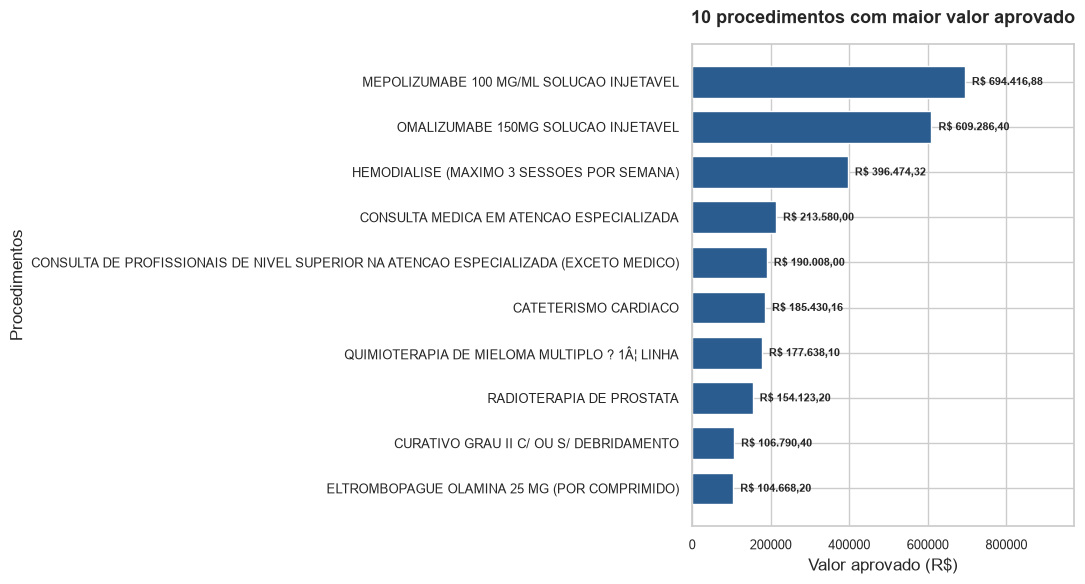

In [33]:
# Procedimentos com maior valor aprovado
proc_valor = (
    tabela.groupby("Procedimento")["pa_valapr"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Montando o gráfico
plt.figure(figsize=(11, 6))

barras = plt.barh(
    proc_valor.index,
    proc_valor.values,
    color=COR_PRINCIPAL,
    height=0.7
)

# Deixar os valores em reais
rotulos = [
    f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    for valor in proc_valor.values
]

# Valores nas barras
plt.bar_label(
    barras,
    labels=rotulos,
    padding=5,
    fontsize=8,
    fontweight="bold"
)

plt.title("10 procedimentos com maior valor aprovado", pad=15)
plt.xlabel("Valor aprovado (R$)")
plt.ylabel("Procedimentos")

plt.xticks(fontsize=9)
plt.yticks(fontsize=9)

# Para os valores não ficarem cortados
plt.xlim(0, proc_valor.max() * 1.40)

plt.tight_layout()
plt.show()

O procedimento com maior valor aprovado foi o de mepolizumabe, com aproximadamente R$ 694 mil, seguido pelo omalizumabe, com R$ 609 mil. A hemodiálise também teve destaque, com mais ou menos R$ 396 mil. Isso mostra que alguns procedimentos tiveram valores aprovados bem maiores que os outros.

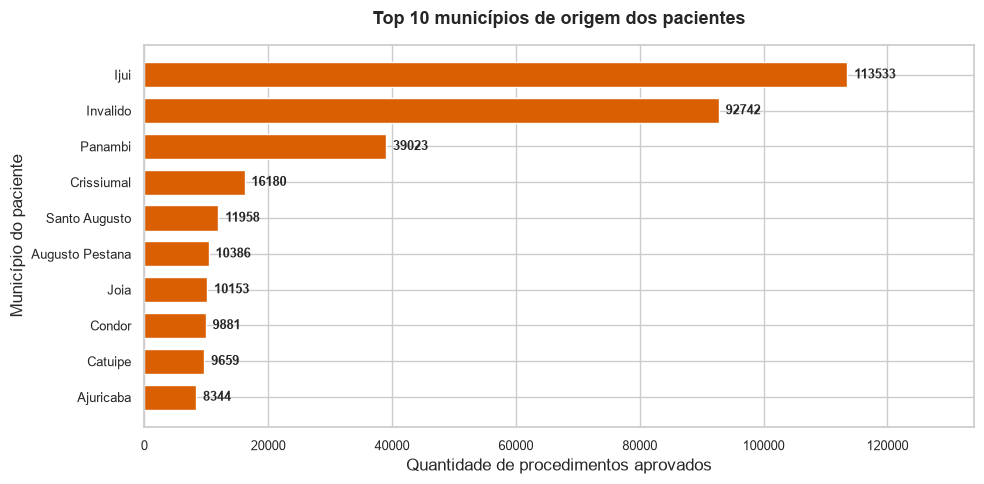

In [34]:
# Quantidade de procedimentos aprovados por município de residência dos pacientes
mun_pac = (
    tabela.assign(
        MunicipioPaciente=tabela["MunicipioPaciente"].fillna("Não informado")
    )
    .groupby("MunicipioPaciente")["pa_qtdapr"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Montando o gráfico
plt.figure(figsize=(10, 5))

barras = plt.barh(
    mun_pac.index.fillna("Não informado"),
    mun_pac.values,
    color=COR_DESTAQUE,
    height=0.7
)

# Valores nas barras
plt.bar_label(
    barras,
    padding=5,
    fmt="%.0f",
    fontsize=9,
    fontweight="bold"
)

plt.title("Top 10 municípios de origem dos pacientes", pad=15)
plt.xlabel("Quantidade de procedimentos aprovados")
plt.ylabel("Município do paciente")

plt.xticks(fontsize=9)
plt.yticks(fontsize=9)

# Para os valores não ficarem cortados
plt.xlim(0, mun_pac.max() * 1.18)

plt.tight_layout()
plt.show()

Ijuí aparece em primeiro lugar com 113.533 procedimentos aprovados seguido pela categoria de município inválido com 92.742. Entre os municípios identificados, Panambi ocupa o segundo lugar com 39.023 e também aparecem outras cidades da região como Crissiumal, Santo Augusto e Augusto Pestana.

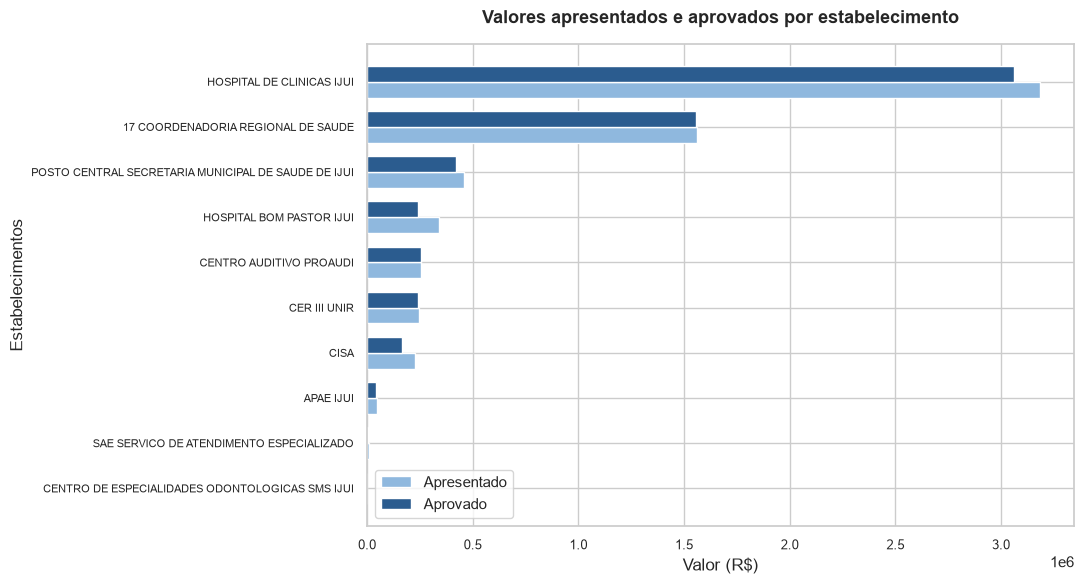

In [35]:
# Estabelecimentos com maior valor apresentado e aprovado
fin_estab = (
    tabela.groupby("Estabelecimento", as_index=False)
    .agg(
        ValorApresentado=("pa_valpro", "sum"),
        ValorAprovado=("pa_valapr", "sum")
    )
    .sort_values("ValorApresentado", ascending=False)
    .head(10)
    .sort_values("ValorApresentado")
)

# Montando o gráfico
plt.figure(figsize=(11, 6))

posicoes = range(len(fin_estab))
altura = 0.35

barras1 = plt.barh(
    [p - altura/2 for p in posicoes],
    fin_estab["ValorApresentado"],
    height=altura,
    color=COR_SECUNDARIA,
    label="Apresentado"
)

barras2 = plt.barh(
    [p + altura/2 for p in posicoes],
    fin_estab["ValorAprovado"],
    height=altura,
    color=COR_PRINCIPAL,
    label="Aprovado"
)

plt.yticks(posicoes, fin_estab["Estabelecimento"])

plt.title("Valores apresentados e aprovados por estabelecimento", pad=15)
plt.xlabel("Valor (R$)")
plt.ylabel("Estabelecimentos")

plt.xticks(fontsize=9)
plt.yticks(fontsize=8)

# Legenda
plt.legend()

plt.tight_layout()
plt.show()

O Hospital de Clínicas de Ijuí apresentou os maiores valores seguido pela 17ª Coordenadoria Regional de Saúde. Também é possível observar diferenças entre os valores apresentados e aprovados em alguns estabelecimentos, principalmente no Hospital Bom Pastor e no Posto Central.

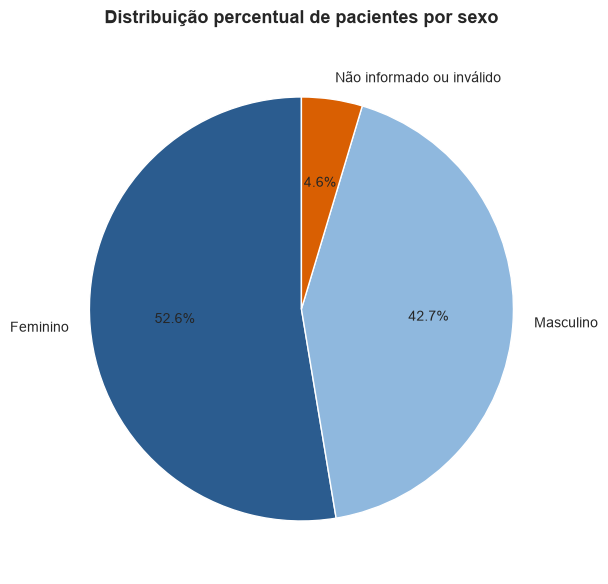

In [36]:
# Quantidade de registros por sexo
sexo_counts = tabela["Sexo"].value_counts()

# Montando o gráfico
plt.figure(figsize=(8, 6))

plt.pie(
    sexo_counts,
    labels=sexo_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[COR_PRINCIPAL, COR_SECUNDARIA, COR_DESTAQUE],
    textprops={"fontsize": 10},
    wedgeprops={"edgecolor": "white", "linewidth": 1}
)

plt.title("Distribuição percentual de pacientes por sexo", pad=15)

plt.tight_layout()
plt.show()

A maior parte dos pacientes é do sexo feminino representando 52,6% dos registros. Já o sexo masculino corresponde a 42,7% enquanto 4,6% dos registros possuem informações não informadas ou inválidas.

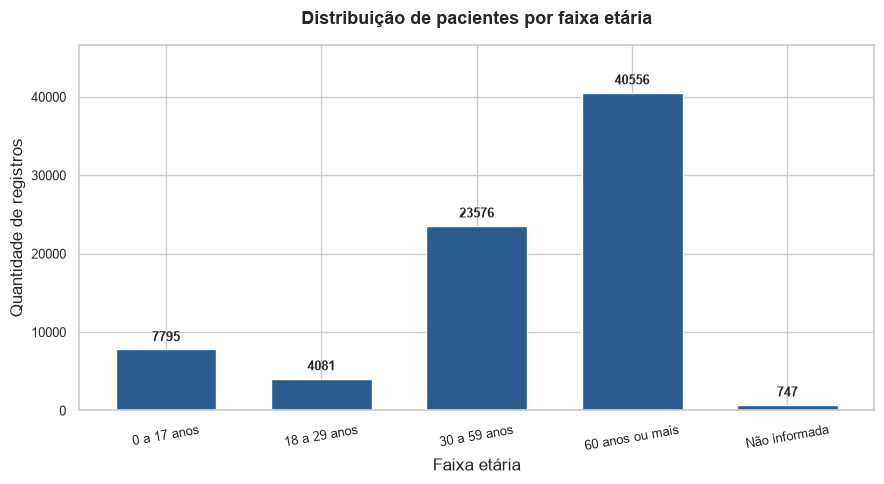

In [37]:
# Quantidade de registros por faixa etária
idade_counts = tabela["FaixaEtaria"].value_counts().reindex([
    "0 a 17 anos",
    "18 a 29 anos",
    "30 a 59 anos",
    "60 anos ou mais",
    "Não informada"
])

# Montando o gráfico
plt.figure(figsize=(9, 5))

barras = plt.bar(
    idade_counts.index,
    idade_counts.values,
    color=COR_PRINCIPAL,
    width=0.65
)

# Valores nas barras
plt.bar_label(
    barras,
    padding=4,
    fmt="%.0f",
    fontsize=9,
    fontweight="bold"
)

plt.title("Distribuição de pacientes por faixa etária", pad=15)
plt.xlabel("Faixa etária")
plt.ylabel("Quantidade de registros")

plt.xticks(rotation=10, fontsize=9)
plt.yticks(fontsize=9)

# Para não cortar as barras
plt.ylim(0, idade_counts.max() * 1.15)

plt.tight_layout()
plt.show()

A maior parte dos pacientes tem 60 anos ou mais com 40.556 registros. Em seguida, aparecem os pacientes de 30 a 59 anos com 23.576 registros. Isso mostra que os atendimentos estão mais concentrados nas faixas etárias acima dos 30 anos.

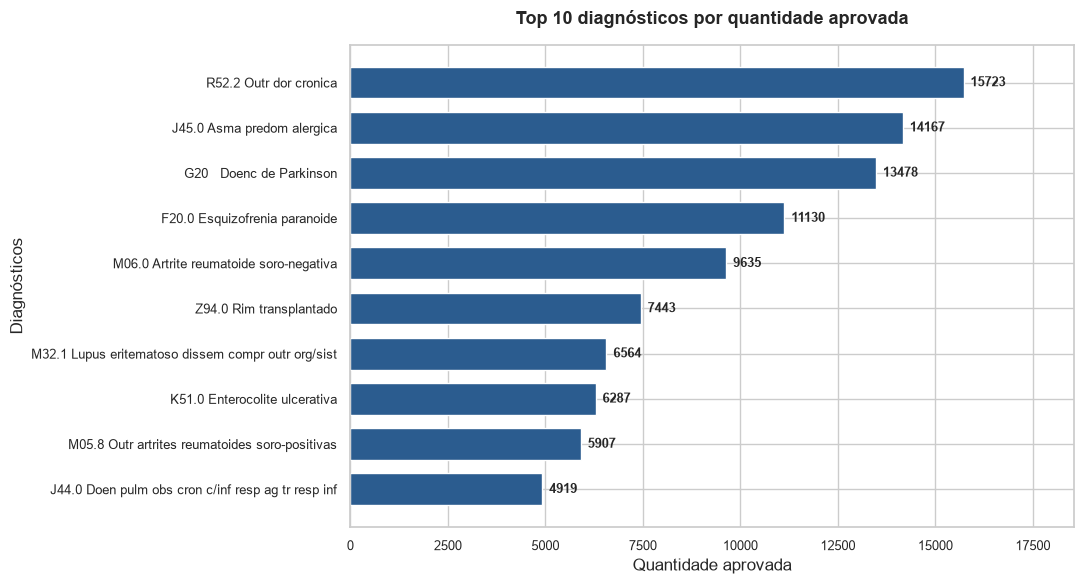

In [38]:
# Diagnósticos com maior quantidade aprovada
top_diag = (
    tabela[
        ~tabela["Diagnostico"].isin([
            "CID NAO INFORMADO",
            "CID N O IDENTIFICADO"
        ])
    ]
    .groupby("Diagnostico")["pa_qtdapr"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Montando o gráfico
plt.figure(figsize=(11, 6))

barras = plt.barh(
    top_diag.index,
    top_diag.values,
    color=COR_PRINCIPAL,
    height=0.7
)

# Valores nas barras
plt.bar_label(
    barras,
    padding=5,
    fmt="%.0f",
    fontsize=9,
    fontweight="bold"
)

plt.title("Top 10 diagnósticos por quantidade aprovada", pad=15)
plt.xlabel("Quantidade aprovada")
plt.ylabel("Diagnósticos")

plt.xticks(fontsize=9)
plt.yticks(fontsize=9)

# Para os valores não ficarem cortados
plt.xlim(0, top_diag.max() * 1.18)

plt.tight_layout()
plt.show()

O diagnóstico com maior quantidade aprovada foi a dor crônica com 15.723 registros, seguido pela asma com 14.167 e pela doença de Parkinson com 13.478. Também aparecem entre os mais frequentes a esquizofrenia e a artrite reumatoide.

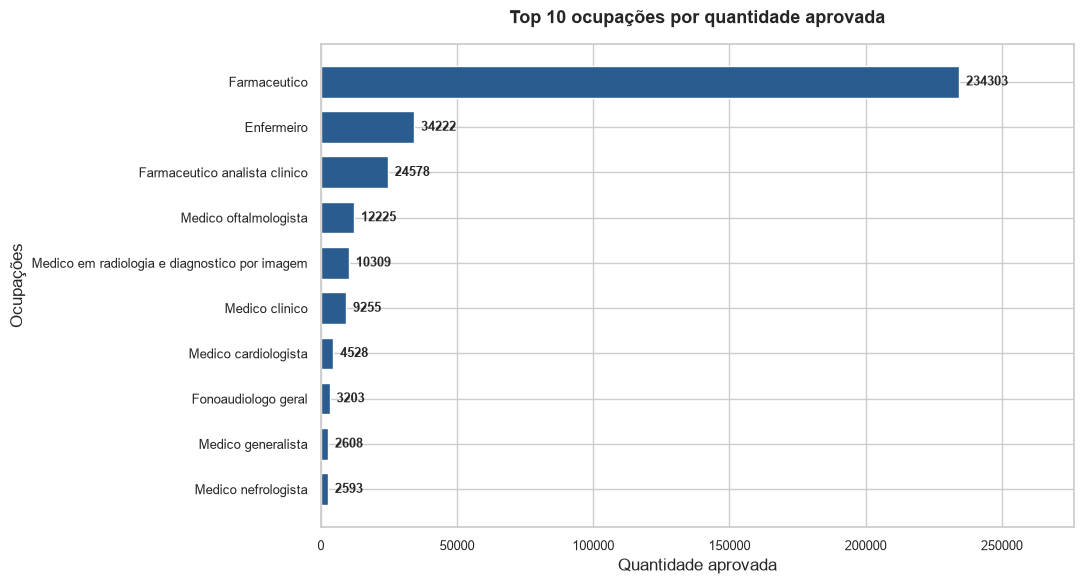

In [39]:
# Ocupações com maior quantidade aprovada
top_ocup = (
    tabela.groupby("Ocupacao")["pa_qtdapr"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Montando o gráfico
plt.figure(figsize=(11, 6))

barras = plt.barh(
    top_ocup.index,
    top_ocup.values,
    color=COR_PRINCIPAL,
    height=0.7
)

# Valores nas barras
plt.bar_label(
    barras,
    padding=5,
    fmt="%.0f",
    fontsize=9,
    fontweight="bold"
)

plt.title("Top 10 ocupações por quantidade aprovada", pad=15)
plt.xlabel("Quantidade aprovada")
plt.ylabel("Ocupações")

plt.xticks(fontsize=9)
plt.yticks(fontsize=9)

# Para os valores não ficarem cortados
plt.xlim(0, top_ocup.max() * 1.18)

plt.tight_layout()
plt.show()

A ocupação com maior quantidade aprovada foi a de farmacêutico com 234.303 registros ficando bemn na frente dos outros. Em seguida, aparecem enfermeiros com 34.222 e farmacêuticos analistas clínicos com 24.578 registros.

## 6. Considerações finais

Foi possível conhecer melhor os dados da produção ambulatorial de Ijuí durante o mês de agosto de 2026. Ao todo foram analisados 76.755 registros com 373.623 procedimentos aprovados e um valor total aprovado de R$ 5.993.695,25.

As análises e os gráficos ajudaram a identificar os procedimentos, estabelecimentos e diagnósticos com maior destaque além de mostrar o perfil dos pacientes atendidos. Também foi possível observar que boa parte dos registros corresponde a pacientes com 60 anos ou mais e que os atendimentos não se limitam apenas aos moradores de Ijuí.

Durante o trabalho também foram encontrados alguns dados ausentes e possíveis duplicidades que exigiram cuidado na preparação da base. Como foram utilizados dados de apenas um mês, não foi possível comparar a produção ao longo do tempo. Mesmo assim, o trabalho permitiu entender melhor as informações disponíveis e conhecer algumas características dos atendimentos realizados no município.